# 02 Procedural synthetic generator
The original data source of the project: a simplified geometric skull and face (not anatomy; see `docs/GENERATOR.md`). A tiny build in a
temporary folder shows what it produces. The real-skull experiment replaces the procedural skull by real scans but keeps this pipeline.

In [1]:
import sys, pathlib, os, json
ROOT = pathlib.Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
REAL, RUN, RES = 'UNCERTAFACE_DATA_REAL', 'experiments/runs/face_v3_pn', 'reports/results/face_v3_pn'
if not pathlib.Path(REAL).exists():
    raise SystemExit('Build the real-skull dataset first (README: fetch_mug500, prepare_mug500, build_dataset).')

In [2]:
import tempfile, yaml
from src.data import build_dataset as bd, mesh_utils as mu
cfg = yaml.safe_load(open('configs/dataset.yaml'))
tmp = tempfile.mkdtemp()
rep = bd.build_dataset(cfg, tmp, n_base=8, obs_per_base=2, source='procedural', log=lambda *a: None)
print(json.dumps(rep['counts'], indent=1)); print('all checks passed:', rep['all_checks_passed'], '| synthetic:', rep['synthetic'])

{
 "independent_base_geometries": 8,
 "observations": 16,
 "base_per_split": {
  "train": 5,
  "validation": 1,
  "calibration": 1,
  "test": 1
 },
 "observations_per_split": {
  "train": 10,
  "validation": 2,
  "calibration": 2,
  "test": 2
 }
}
all checks passed: True | synthetic: True


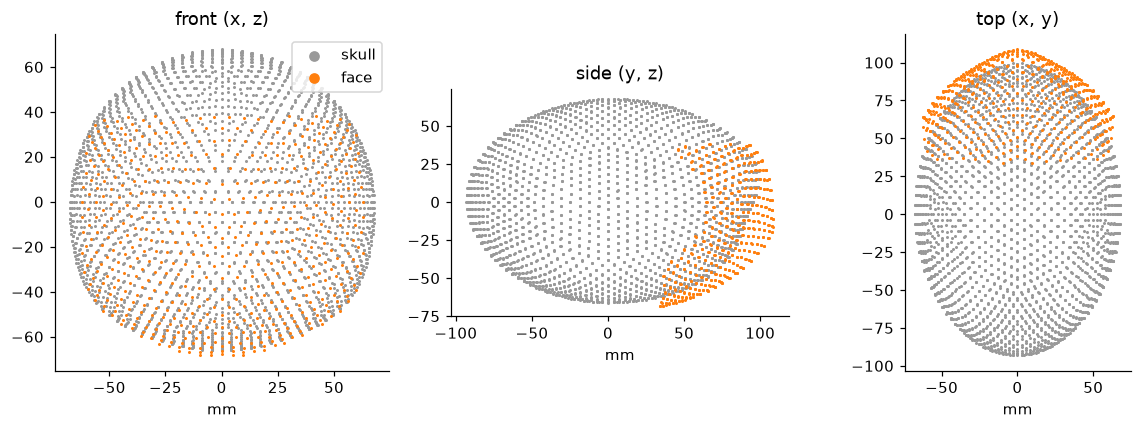

In [3]:
%matplotlib inline
from pathlib import Path
sv, sf = mu.load_mesh(str(Path(tmp) / 'raw/generated/cranial_meshes/B0000.ply'))
fv, ff = mu.load_mesh(str(Path(tmp) / 'raw/generated/facial_meshes/B0000.ply'))
fig, ax = plt.subplots(1, 3, figsize=(11, 4))
for a, (i, j, t) in zip(ax, [(0, 2, 'front (x, z)'), (1, 2, 'side (y, z)'), (0, 1, 'top (x, y)')]):
    a.scatter(sv[:, i], sv[:, j], s=1, c='0.6', label='skull'); a.scatter(fv[:, i], fv[:, j], s=1, c='tab:orange', label='face')
    a.set_title(t); a.set_aspect('equal'); a.set_xlabel('mm')
ax[0].legend(markerscale=6); plt.tight_layout(); plt.show()

In [4]:
print(open('docs/GENERATOR.md', encoding='utf-8').read()[:1800])

# Synthetic generator: model and assumptions

**Everything generated here is synthetic.** The generator (`src/data/generator.py`) is a simplified geometric research
prototype. It is **not** an anatomical simulation, and nothing it produces is real human, forensic, or clinical data.

## Asset audit
No real paired skull-face dataset was available in the execution environment, and none was downloaded, scraped or
redistributed. Parametric face models with restrictive licences (e.g. statistical head models) were not used. The default
and only data source is the procedural generator below.

| Asset | Source | Licence | Real/synthetic | Paired correspondence |
|---|---|---|---|---|
| `UNCERTAFACE_DATA` | `src/data/generator.py` (this repo) | repository licence (see `LICENSE`) | procedural, synthetic | exact, by construction |

## Geometry (units: mm; +x right, +y anterior, +z superior; origin at the cranial centre)
**Skull.** A deformed ellipsoid on a fixed icosphere topology (2562 vertices).